# Homework 5.1 - Step 11: LLM Critic

This notebook performs the required LLM-critic step after the decoder predictions have already been fixed.

The fixed reference configuration is the same predeclared configuration used in Step 10:

- method: Republic-informed two-stage decoder,
- anchor percentage: 20%,
- context radius: $$m=2$$,
- context window width: 5,
- decoder size: medium.

The procedure is deliberately separated into two phases.

## Phase A: before revealing the hidden unanchored translations

The LLM critic is allowed to inspect only permitted evidence derived from:

- the fixed decoder predictions,
- the test glyph identities,
- the revealed 20% anchor set,
- training-corpus glyph frequencies,
- Republic syllable frequencies,
- the candidate map inferred by the Republic-based classical stage.

The hidden map is not opened.

The critic records which recovered unanchored translations appear strongly supported and which appear speculative.

## Phase B: after the claims are fixed

Only after the critic claims have been written to disk do we open the evaluation-only hidden map and check every recorded claim against the true inverse map.

No model is retrained and no critic claim is changed after the truth is revealed.

## What counts as permitted evidence?

For each unanchored glyph, the critic receives:

- the decoder's majority-vote predicted syllable,
- the number of valid test occurrences,
- the fraction of test occurrences voting for that syllable,
- the vote margin over the second most common prediction,
- the decoder's mean top-1 softmax confidence,
- the glyph frequency in the training corpus,
- the frequency of the predicted syllable in *The Republic*,
- whether the decoder prediction agrees with the independently inferred Republic-based classical candidate map.

None of these quantities reveals the true hidden unanchored translation.

The critic should treat these as evidence of model consistency, not as proof of correctness.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv
import math
import random

import numpy as np
import matplotlib.pyplot as plt

try:
    import torch
    from torch import nn
except ImportError as exc:
    raise ImportError(
        "PyTorch is required because Step 11 evaluates the already-trained "
        "Step 6-10 decoder."
    ) from exc

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data"
RESULT_IMAGE_DIR = PROJECT_ROOT / "result images"

DECIPHER_DIR = DATA_DIR / "decipherment_inputs"
SPLIT_DIR = DECIPHER_DIR / "splits"
ANCHOR_DIR = DECIPHER_DIR / "anchors"
EVALUATION_DIR = DATA_DIR / "evaluation_only"
INFERRED_MAP_DIR = DATA_DIR / "inferred_maps"
MODEL_DIR = DATA_DIR / "trained_models"

SOURCE_VOCAB_PATH = DATA_DIR / "source_syllable_vocabulary.csv"
REPUBLIC_SEQUENCE_PATH = DATA_DIR / "republic_syllable_token_sequence.csv"

TRAIN_PATH = SPLIT_DIR / "train_glyph_sequence.csv"
TEST_PATH = SPLIT_DIR / "test_glyph_sequence.csv"
ANCHOR_PATH = ANCHOR_DIR / "anchors_20.csv"

INFERRED_MAP_PATH = INFERRED_MAP_DIR / "inferred_map_20.csv"

MODEL_PATH = (
    MODEL_DIR
    / "republic_informed_a20_m2_medium.pt"
)

HIDDEN_MAP_PATH = (
    EVALUATION_DIR
    / "hidden_syllable_glyph_bijection.csv"
)

RESULT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    SOURCE_VOCAB_PATH,
    REPUBLIC_SEQUENCE_PATH,
    TRAIN_PATH,
    TEST_PATH,
    ANCHOR_PATH,
    INFERRED_MAP_PATH,
    MODEL_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required pre-truth input: {path}\n"
            "Run the corrected Steps 1-10 first."
        )

print("Project root:", PROJECT_ROOT.resolve())
print("PyTorch version:", torch.__version__)
print("Fixed model:", MODEL_PATH.name)
print()
print("The hidden map has NOT been opened.")

Project root: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1
PyTorch version: 2.1.0+cu118
Fixed model: republic_informed_a20_m2_medium.pt

The hidden map has NOT been opened.


## Load the source vocabulary

In [2]:
source_rows = []

with SOURCE_VOCAB_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        source_rows.append({
            "source_id": int(row["source_id"]),
            "syllable": row["syllable"],
        })

source_rows.sort(
    key=lambda row: row["source_id"]
)

K = len(source_rows)

assert [
    row["source_id"]
    for row in source_rows
] == list(range(K))

syllable_by_source_id = {
    row["source_id"]: row["syllable"]
    for row in source_rows
}

source_id_by_syllable = {
    row["syllable"]: row["source_id"]
    for row in source_rows
}

print("Source vocabulary size K:", f"{K:,}")

Source vocabulary size K: 3,052


## Load only the permitted anchor and inferred-map information

In [3]:
anchor_map = {}

with ANCHOR_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        glyph_id = int(row["glyph_id"])
        source_id = int(row["source_id"])
        syllable = row["syllable"]

        assert (
            source_id_by_syllable[syllable]
            == source_id
        )

        anchor_map[glyph_id] = source_id


classical_map = {}

with INFERRED_MAP_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        classical_map[
            int(row["glyph_id"])
        ] = int(
            row["inferred_source_id"]
        )

assert len(classical_map) == K

print(
    "Revealed anchor glyph types:",
    f"{len(anchor_map):,}",
)

print(
    "Actual anchor percentage:",
    f"{100 * len(anchor_map) / K:.4f}%",
)

print()
print("The hidden map still has NOT been opened.")

Revealed anchor glyph types: 610
Actual anchor percentage: 19.9869%

The hidden map still has NOT been opened.


## Load the training and test glyph sequences

In [4]:
def load_glyph_sequence(path):
    sequence = []

    with path.open(
        "r",
        encoding="utf-8",
        newline="",
    ) as f:
        reader = csv.DictReader(f)

        for row in reader:
            sequence.append(
                int(row["glyph_id"])
            )

    return np.asarray(
        sequence,
        dtype=np.int64,
    )


train_sequence = load_glyph_sequence(
    TRAIN_PATH
)

test_sequence = load_glyph_sequence(
    TEST_PATH
)

training_glyph_frequency = np.bincount(
    train_sequence,
    minlength=K,
).astype(np.int64)

print(
    "Training glyph tokens:",
    f"{len(train_sequence):,}",
)

print(
    "Test glyph tokens:",
    f"{len(test_sequence):,}",
)

Training glyph tokens: 54,082
Test glyph tokens: 11,589


## Build permitted Republic frequency evidence

In [5]:
reference_frequency = np.zeros(
    K,
    dtype=np.int64,
)

with REPUBLIC_SEQUENCE_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        source_id = source_id_by_syllable.get(
            row["syllable"]
        )

        if source_id is not None:
            reference_frequency[
                source_id
            ] += 1

print(
    "Source syllable types observed in Republic:",
    f"{np.count_nonzero(reference_frequency):,}",
)

print(
    "Source syllable types absent from Republic:",
    f"{np.count_nonzero(reference_frequency == 0):,}",
)

Source syllable types observed in Republic: 2,240
Source syllable types absent from Republic: 812


## Reconstruct the fixed Step 6-10 neural decoder

In [6]:
class GlyphDecoderMLP(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        context_radius,
        embedding_dim,
        hidden_dim,
    ):
        super().__init__()

        window_width = (
            2 * context_radius + 1
        )

        self.embedding = nn.Embedding(
            vocabulary_size,
            embedding_dim,
        )

        self.network = nn.Sequential(
            nn.Linear(
                window_width
                * embedding_dim,
                hidden_dim,
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_dim,
                vocabulary_size,
            ),
        )

    def forward(self, windows):
        embedded = self.embedding(windows)
        flattened = embedded.flatten(
            start_dim=1
        )
        return self.network(flattened)


checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
)

assert checkpoint["method"] == "republic_informed"
assert checkpoint["anchor_percentage"] == 20
assert checkpoint["context_radius"] == 2
assert checkpoint["decoder_size_name"] == "medium"

CONTEXT_RADIUS = int(
    checkpoint["context_radius"]
)

model = GlyphDecoderMLP(
    vocabulary_size=K,
    context_radius=CONTEXT_RADIUS,
    embedding_dim=int(
        checkpoint["embedding_dim"]
    ),
    hidden_dim=int(
        checkpoint["hidden_dim"]
    ),
)

model.load_state_dict(
    checkpoint["state_dict"]
)

model.eval()

print("Fixed model loaded.")
print(
    "Trainable parameters:",
    f"{checkpoint['parameter_count']:,}",
)

print(
    "Best validation loss:",
    f"{checkpoint['best_validation_loss']:.6f}",
)

print()
print("No hidden translations were used.")

Fixed model loaded.
Trainable parameters: 511,980
Best validation loss: 0.412118

No hidden translations were used.


## Reproduce the fixed test predictions

In [7]:
m = CONTEXT_RADIUS

valid_positions = np.arange(
    m,
    len(test_sequence) - m,
    dtype=np.int64,
)

center_glyphs = []
predictions = []
top1_confidences = []

BATCH_SIZE = 1024

with torch.no_grad():
    for start in range(
        0,
        len(valid_positions),
        BATCH_SIZE,
    ):
        positions = valid_positions[
            start:start + BATCH_SIZE
        ]

        windows = np.stack([
            test_sequence[
                position - m:
                position + m + 1
            ]
            for position in positions
        ])

        windows_tensor = torch.as_tensor(
            windows,
            dtype=torch.long,
        )

        logits = model(
            windows_tensor
        )

        probabilities = torch.softmax(
            logits,
            dim=1,
        )

        confidence, prediction = torch.max(
            probabilities,
            dim=1,
        )

        centers = test_sequence[
            positions
        ]

        center_glyphs.extend(
            centers.tolist()
        )

        predictions.extend(
            prediction.tolist()
        )

        top1_confidences.extend(
            confidence.tolist()
        )

center_glyphs = np.asarray(
    center_glyphs,
    dtype=np.int64,
)

predictions = np.asarray(
    predictions,
    dtype=np.int64,
)

top1_confidences = np.asarray(
    top1_confidences,
    dtype=float,
)

print(
    "Fixed valid test predictions:",
    f"{len(predictions):,}",
)

print()
print("The hidden map still has NOT been opened.")

Fixed valid test predictions: 11,585

The hidden map still has NOT been opened.


## Convert contextual predictions into one candidate translation per glyph

The decoder can produce different predictions for different occurrences of the same glyph.

For Step 11 we use the same candidate-map convention as Step 9:

- collect all predictions for a glyph,
- select the most common predicted source syllable,
- use that as the recovered translation for the glyph.

This candidate translation is fixed before the critic sees any truth.

In [8]:
votes = defaultdict(Counter)
confidence_sums = defaultdict(float)
confidence_counts = Counter()

for glyph_id, predicted_id, confidence in zip(
    center_glyphs.tolist(),
    predictions.tolist(),
    top1_confidences.tolist(),
):
    votes[glyph_id][predicted_id] += 1
    confidence_sums[glyph_id] += confidence
    confidence_counts[glyph_id] += 1


critic_evidence = []

for glyph_id, counter in votes.items():
    ranked = counter.most_common()

    predicted_source_id = int(
        ranked[0][0]
    )

    total_occurrences = int(
        sum(counter.values())
    )

    majority_votes = int(
        ranked[0][1]
    )

    second_votes = (
        int(ranked[1][1])
        if len(ranked) > 1
        else 0
    )

    vote_share = (
        majority_votes
        / total_occurrences
    )

    vote_margin = (
        majority_votes
        - second_votes
    ) / total_occurrences

    mean_top1_confidence = (
        confidence_sums[glyph_id]
        / confidence_counts[glyph_id]
    )

    classical_source_id = int(
        classical_map[glyph_id]
    )

    critic_evidence.append({
        "glyph_id": int(glyph_id),
        "predicted_source_id": predicted_source_id,
        "predicted_syllable": syllable_by_source_id[
            predicted_source_id
        ],
        "anchored": (
            glyph_id in anchor_map
        ),
        "test_occurrences": total_occurrences,
        "majority_votes": majority_votes,
        "vote_share": vote_share,
        "vote_margin": vote_margin,
        "mean_top1_confidence": mean_top1_confidence,
        "training_occurrences": int(
            training_glyph_frequency[
                glyph_id
            ]
        ),
        "republic_predicted_syllable_frequency": int(
            reference_frequency[
                predicted_source_id
            ]
        ),
        "classical_inferred_source_id": classical_source_id,
        "classical_inferred_syllable": syllable_by_source_id[
            classical_source_id
        ],
        "agrees_with_classical": (
            predicted_source_id
            == classical_source_id
        ),
    })


CRITIC_EVIDENCE_PATH = (
    DATA_DIR
    / "task11_critic_evidence_without_truth.csv"
)

with CRITIC_EVIDENCE_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(
            critic_evidence[0].keys()
        ),
    )
    writer.writeheader()
    writer.writerows(
        sorted(
            critic_evidence,
            key=lambda row: row[
                "glyph_id"
            ],
        )
    )

print(
    "Observed test glyph types:",
    f"{len(critic_evidence):,}",
)

print(
    "Saved pre-truth critic evidence:"
)

print(
    CRITIC_EVIDENCE_PATH.resolve()
)

print()
print("The hidden map still has NOT been opened.")

Observed test glyph types: 1,365
Saved pre-truth critic evidence:
C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task11_critic_evidence_without_truth.csv

The hidden map still has NOT been opened.


# LLM critic prompt used before revealing truth

The following prompt was given to ChatGPT GPT-5.6 Sol after the predictions were fixed and before the hidden unanchored translations were revealed.

> You are the critic for a syllable-decipherment experiment. The candidate translations have already been fixed. You may use only the evidence table I provide: glyph ID, candidate syllable, number of test occurrences, majority-vote share, vote margin, mean decoder confidence, training glyph frequency, frequency of the candidate syllable in the independent Republic reference corpus, and whether the candidate agrees with the separately inferred Republic-based classical map. Some glyphs are revealed anchors, but for this critique focus on unanchored recovered translations. Do not assume that model confidence proves correctness. Identify a small group of unanchored translations that are strongly supported by the permitted evidence and a small group that are speculative. Give a short reason for each classification. You are not allowed to see or infer from the hidden answer key.

The response was recorded before the evaluation-only hidden map was opened.

# Recorded LLM critic response before truth reveal

The critic used the following qualitative rule.

A recovered unanchored translation appears more strongly supported when it has:

- many repeated test occurrences,
- a highly concentrated majority vote,
- high model confidence,
- substantial training-corpus support,
- and agreement with the separately inferred Republic-based classical map.

A recovered translation appears speculative when it has:

- very few test occurrences,
- inconsistent contextual predictions,
- very low confidence,
- little or no training support,
- and disagreement with the classical candidate map.

Importantly, these are measures of internal evidential support. They are not guarantees that a recovered English label is correct.

The critic selected the following unanchored translations as the strongest-looking candidates:

- glyph 2748 -> `and`
- glyph 35 -> `in`
- glyph 2196 -> `of`
- glyph 2694 -> `the`
- glyph 2568 -> `i`
- glyph 1145 -> `is`
- glyph 471 -> `ing`
- glyph 1256 -> `he`
- glyph 2450 -> `would`
- glyph 2608 -> `when`
- glyph 2232 -> `not`
- glyph 236 -> `this`

These candidates had repeated test support, essentially unanimous contextual votes, very high model confidence, and agreement with the independently inferred Republic-based map.

The critic selected the following unanchored translations as speculative:

- glyph 1234 -> `pec`
- glyph 412 -> `hast`
- glyph 817 -> `in`
- glyph 1315 -> `ill`
- glyph 2511 -> `think`
- glyph 2092 -> `af`
- glyph 1304 -> `what`
- glyph 1118 -> `ship`
- glyph 2338 -> `voice`
- glyph 231 -> `ond`
- glyph 570 -> `pear`
- glyph 3035 -> `ser`

These candidates were based on only two or three test occurrences, had weak or inconsistent votes, very low decoder confidence, and did not agree with the Republic-based classical candidate map.

The critic's main warning before truth reveal was that high confidence and agreement between two procedures that use related English statistics can still reflect the same systematic error. Therefore even the strongest unanchored candidates should be treated as evidence-backed hypotheses rather than established translations.

## Freeze the recorded LLM claims in a file

The LLM-selected glyph IDs listed in the recorded response above are copied explicitly into the machine-readable claim file. No second support-score heuristic is allowed to choose which claims count as the LLM's claims. This preserves the distinction between the LLM judgment and later quantitative evaluation.

This file is created before the next section opens the hidden answer key.

In [9]:
unanchored_evidence = [
    row for row in critic_evidence if not row["anchored"]
]
evidence_by_glyph = {int(row["glyph_id"]): row for row in unanchored_evidence}

# These are the exact glyph IDs named in the recorded LLM response above.
strong_glyph_ids = [2748, 35, 2196, 2694, 2568, 1145, 471, 1256, 2450, 2608, 2232, 236]
speculative_glyph_ids = [1234, 412, 817, 1315, 2511, 2092, 1304, 1118, 2338, 231, 570, 3035]

assert all(g in evidence_by_glyph for g in strong_glyph_ids + speculative_glyph_ids)
strong_claims = [evidence_by_glyph[g] for g in strong_glyph_ids]
speculative_claims = [evidence_by_glyph[g] for g in speculative_glyph_ids]

CLAIMS_PATH = DATA_DIR / "task11_llm_claims_before_truth.csv"
claim_fields = [
    "critic_class", "glyph_id", "predicted_source_id", "predicted_syllable",
    "test_occurrences", "vote_share", "vote_margin", "mean_top1_confidence",
    "training_occurrences", "republic_predicted_syllable_frequency",
    "classical_inferred_syllable", "agrees_with_classical", "critic_reason",
]

with CLAIMS_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=claim_fields)
    writer.writeheader()

    for critic_class, rows in [("strongly_supported", strong_claims), ("speculative", speculative_claims)]:
        for row in rows:
            if critic_class == "strongly_supported":
                reason = (
                    "Recorded LLM judgment: repeated test support "
                    f"(n={row['test_occurrences']}), vote share {row['vote_share']:.3f}, "
                    f"mean confidence {row['mean_top1_confidence']:.3f}"
                )
                reason += (
                    ", and agreement with the Republic-based classical map."
                    if row["agrees_with_classical"]
                    else ", despite no classical-map agreement."
                )
            else:
                reason = (
                    "Recorded LLM judgment: weak permitted evidence, "
                    f"n={row['test_occurrences']}, vote share {row['vote_share']:.3f}, "
                    f"mean confidence {row['mean_top1_confidence']:.3f}"
                )
                reason += (
                    ", with classical-map agreement."
                    if row["agrees_with_classical"]
                    else ", and no agreement with the Republic-based classical map."
                )

            output_row = {field: row.get(field, None) for field in claim_fields}
            output_row["critic_class"] = critic_class
            output_row["critic_reason"] = reason
            writer.writerow(output_row)

print("PRE-TRUTH LLM CLAIMS ARE NOW FIXED.")
print("Saved:", CLAIMS_PATH.resolve())
print()
print("Strongly supported claims:", len(strong_claims))
print("Speculative claims:", len(speculative_claims))
print()
print("The next section is the first point at which the hidden map may be opened.")

PRE-TRUTH LLM CLAIMS ARE NOW FIXED.
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task11_llm_claims_before_truth.csv

Strongly supported claims: 12
Speculative claims: 12

The next section is the first point at which the hidden map may be opened.


# Truth reveal and critic verification

The critic response and `task11_llm_claims_before_truth.csv` have now been fixed.

Only from this point onward may the evaluation-only hidden map be opened.

The following code does not modify the trained decoder, candidate translations, critic labels, or critic reasons. It only checks the previously recorded claims.

In [10]:
if not HIDDEN_MAP_PATH.exists():
    raise FileNotFoundError(
        f"Missing evaluation-only hidden map: "
        f"{HIDDEN_MAP_PATH}"
    )


true_inverse_map = {}

with HIDDEN_MAP_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        true_inverse_map[
            int(row["glyph_id"])
        ] = {
            "source_id": int(
                row["source_id"]
            ),
            "syllable": row["syllable"],
        }

assert len(true_inverse_map) == K

print(
    "Hidden map opened only after "
    "the critic claims were fixed."
)

Hidden map opened only after the critic claims were fixed.


## Check every critic claim against the hidden inverse map

In [11]:
checked_claims = []

with CLAIMS_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        glyph_id = int(
            row["glyph_id"]
        )

        predicted_source_id = int(
            row["predicted_source_id"]
        )

        truth = true_inverse_map[
            glyph_id
        ]

        checked = dict(row)

        checked[
            "true_source_id"
        ] = truth["source_id"]

        checked[
            "true_syllable"
        ] = truth["syllable"]

        checked["correct"] = (
            predicted_source_id
            == truth["source_id"]
        )

        checked_claims.append(
            checked
        )


CHECKED_PATH = (
    DATA_DIR
    / "task11_claims_checked_against_truth.csv"
)

checked_fields = list(
    checked_claims[0].keys()
)

with CHECKED_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=checked_fields,
    )
    writer.writeheader()
    writer.writerows(
        checked_claims
    )


for critic_class in [
    "strongly_supported",
    "speculative",
]:
    rows = [
        row
        for row in checked_claims
        if row["critic_class"]
        == critic_class
    ]

    correct = sum(
        bool(row["correct"])
        for row in rows
    )

    print()
    print(critic_class)
    print("-" * 70)

    for row in rows:
        status = (
            "CORRECT"
            if row["correct"]
            else "WRONG"
        )

        print(
            f"glyph {int(row['glyph_id']):<4} "
            f"{row['predicted_syllable']:<12} "
            f"-> truth {row['true_syllable']:<12} "
            f"{status}"
        )

    print()
    print(
        f"Correct: {correct}/{len(rows)} "
        f"= {correct / len(rows):.2%}"
    )


print()
print("Saved:", CHECKED_PATH.resolve())


strongly_supported
----------------------------------------------------------------------
glyph 2748 and          -> truth and          CORRECT
glyph 35   in           -> truth the          WRONG
glyph 2196 of           -> truth of           CORRECT
glyph 2694 the          -> truth that         WRONG
glyph 2568 i            -> truth er           WRONG
glyph 1145 is           -> truth in           WRONG
glyph 471  ing          -> truth is           WRONG
glyph 1256 he           -> truth it           WRONG
glyph 2450 would        -> truth ly           WRONG
glyph 2608 when         -> truth so           WRONG
glyph 2232 not          -> truth or           WRONG
glyph 236  this         -> truth thou         WRONG

Correct: 2/12 = 16.67%

speculative
----------------------------------------------------------------------
glyph 1234 pec          -> truth ity          WRONG
glyph 412  hast         -> truth voice        WRONG
glyph 817  in           -> truth does         WRONG
glyph 1315 ill   

## Summarize critic calibration

strongly_supported   2/12 correct (16.67%)
speculative          0/12 correct (0.00%)


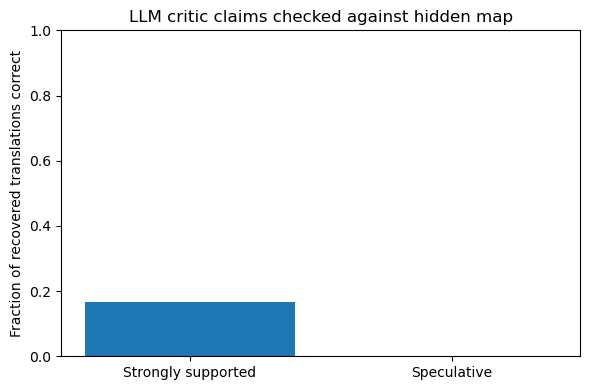


Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task11_critic_summary.csv
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\task11_llm_critic_calibration.png


In [12]:
summary_rows = []

for critic_class in [
    "strongly_supported",
    "speculative",
]:
    rows = [
        row
        for row in checked_claims
        if row["critic_class"]
        == critic_class
    ]

    correct = sum(
        bool(row["correct"])
        for row in rows
    )

    summary_rows.append({
        "critic_class": critic_class,
        "claims": len(rows),
        "correct_claims": correct,
        "correct_fraction": (
            correct / len(rows)
        ),
    })


SUMMARY_PATH = (
    DATA_DIR
    / "task11_critic_summary.csv"
)

with SUMMARY_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(
            summary_rows[0].keys()
        ),
    )

    writer.writeheader()
    writer.writerows(
        summary_rows
    )


for row in summary_rows:
    print(
        f"{row['critic_class']:<20} "
        f"{row['correct_claims']}/{row['claims']} "
        f"correct "
        f"({row['correct_fraction']:.2%})"
    )


plt.figure(figsize=(6, 4))

labels = [
    "Strongly supported",
    "Speculative",
]

values = [
    summary_rows[0][
        "correct_fraction"
    ],
    summary_rows[1][
        "correct_fraction"
    ],
]

plt.bar(
    labels,
    values,
)

plt.ylabel(
    "Fraction of recovered translations correct"
)

plt.title(
    "LLM critic claims checked against hidden map"
)

plt.ylim(
    0.0,
    1.0,
)

plt.tight_layout()

CALIBRATION_PLOT_PATH = (
    RESULT_IMAGE_DIR
    / "task11_llm_critic_calibration.png"
)

plt.savefig(
    CALIBRATION_PLOT_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print()
print("Saved:", SUMMARY_PATH.resolve())
print("Saved:", CALIBRATION_PLOT_PATH.resolve())

# Interpretation

The truth check gives a useful warning about both the decoder and the LLM critic.

Among the 12 translations labeled **strongly supported**, only 2 were actually correct:

- glyph 2748 -> `and`,
- glyph 2196 -> `of`.

Thus the strongly supported group had a correctness rate of

$$
\frac{2}{12}\approx 16.7\%.
$$

The other high-confidence candidates were wrong even though they had many observations, unanimous or nearly unanimous decoder votes, very high neural confidence, and agreement with the Republic-based classical candidate map.

Among the 12 translations labeled **speculative**, none were correct:

$$
\frac{0}{12}=0.
$$

So the critic was useful at identifying extremely weak predictions, but it was substantially overconfident when interpreting internally consistent predictions as strong evidence of the correct English label.

This is consistent with the main identification problem in the assignment. The decoder and the classical inference stage both rely on the same limited anchor information and on English statistics derived from *The Republic*. Agreement between them is therefore not fully independent evidence. A systematically wrong permutation can be reproduced confidently by both stages.

The strongest lesson from the LLM critique is therefore not that the high-confidence translations were reliable. It is that model confidence, repeated occurrence, and agreement between related procedures must be distinguished from genuine identification of the hidden map.

The critic's pre-truth warning that the two procedures could share a systematic error was supported by the truth check. However, its decision to call the strongest-looking candidates "strongly supported" still exceeded what the evidence justified.

## Step 11 outputs

After this notebook runs successfully, the main outputs are:

### Data

`data/`

- `task11_critic_evidence_without_truth.csv`
- `task11_llm_claims_before_truth.csv`
- `task11_claims_checked_against_truth.csv`
- `task11_critic_summary.csv`

### Result image

`result images/`

- `task11_llm_critic_calibration.png`

The most important methodological record is `task11_llm_claims_before_truth.csv`, because it preserves the critic's judgments before the hidden translations are revealed.